In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving cardekho.csv to cardekho.csv


In [3]:
df = pd.read_csv("cardekho.csv")

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [5]:
# Check number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset shape: (8128, 12)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   flo

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
count,8128,8128.000000,8.128000e+03,8.128000e+03,8128,8128,8128,8128,7907.000000,7907.000000,7913,7907.000000
unique,2058,NaN,NaN,NaN,4,3,2,5,NaN,NaN,320,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,NaN,NaN,74,NaN
freq,129,NaN,NaN,NaN,4402,6766,7078,5289,NaN,NaN,377,NaN
mean,NaN,2013.804011,6.382718e+05,6.981951e+04,NaN,NaN,NaN,NaN,19.418783,1458.625016,NaN,5.416719
std,NaN,4.044249,8.062534e+05,5.655055e+04,NaN,NaN,NaN,NaN,4.037145,503.916303,NaN,0.959588
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,0.000000,624.000000,NaN,2.000000
25%,NaN,2011.000000,2.549990e+05,3.500000e+04,NaN,NaN,NaN,NaN,16.780000,1197.000000,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,19.300000,1248.000000,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.800000e+04,NaN,NaN,NaN,NaN,22.320000,1582.000000,NaN,5.000000


In [6]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

Duplicate rows: 1202


In [7]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove extra spaces and standardize categorical text
categorical_columns = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

for col in categorical_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize capitalization for categorical values
for col in ["fuel", "seller_type", "transmission", "owner"]:
    df[col] = df[col].str.title()

# Convert max_power to numeric
# Any non-numeric values become missing values
df["max_power"] = pd.to_numeric(
    df["max_power"].astype(str).str.replace("bhp", "", regex=False).str.strip(),
    errors="coerce"
)

print("Shape after removing duplicates:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Shape after removing duplicates: (6926, 12)

Missing values after cleaning:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    208
engine                208
max_power             206
seats                 208
dtype: int64


In [8]:
# Calculate the age of each car
CURRENT_YEAR = 2026

df["car_age"] = CURRENT_YEAR - df["year"]

# Extract the first word from the car name as its brand
df["brand"] = df["name"].str.split().str[0]

# Show the new features
display(df[["name", "year", "car_age", "brand"]].head(10))

,name,year,car_age,brand
0,Maruti Swift Dzire VDI,2014,12,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,12,Skoda
2,Honda City 2017-2020 EXi,2006,20,Honda
3,Hyundai i20 Sportz Diesel,2010,16,Hyundai
4,Maruti Swift VXI BSIII,2007,19,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,2017,9,Hyundai
6,Maruti Wagon R LXI DUO BSIII,2007,19,Maruti
7,Maruti 800 DX BSII,2001,25,Maruti
8,Toyota Etios VXD,2011,15,Toyota
9,Ford Figo Diesel Celebration Edition,2013,13,Ford


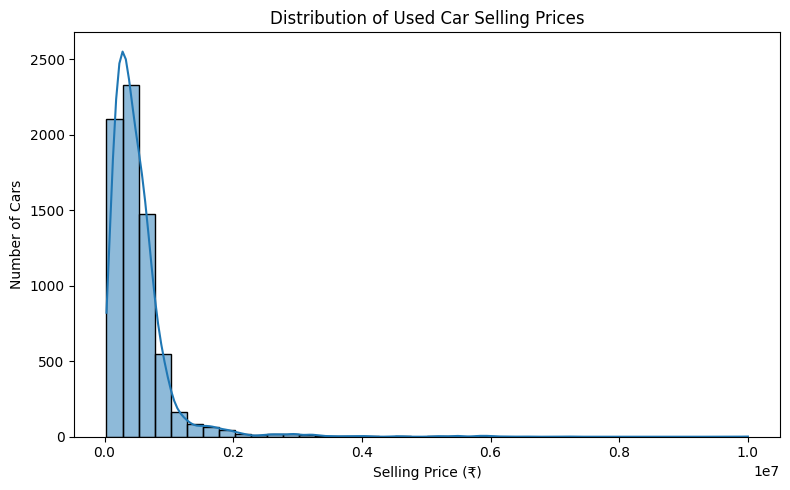

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df["selling_price"], bins=40, kde=True)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

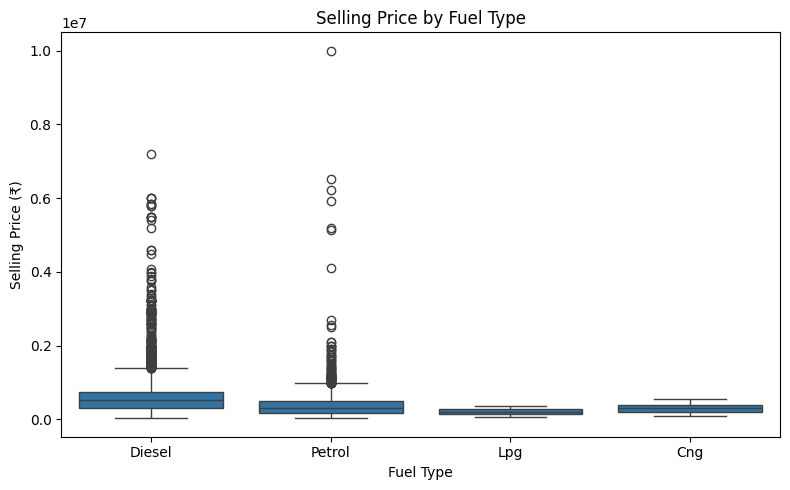

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fuel", y="selling_price")

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

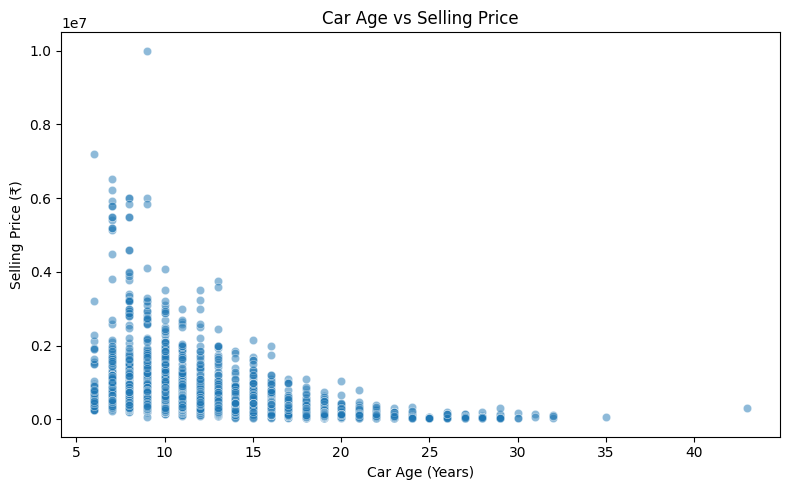

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.5
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")

plt.tight_layout()
plt.show()

In [12]:
# Input features used to predict the selling price
features = [
    "brand",
    "car_age",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats"
]

# X contains the input features
X = df[features].copy()

# y contains the target variable
y = df["selling_price"].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (6926, 11)
Target shape: (6926,)


,brand,car_age,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti,12,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda,12,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda,20,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai,16,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti,19,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0


,selling_price
0,450000
1,370000
2,158000
3,225000
4,130000


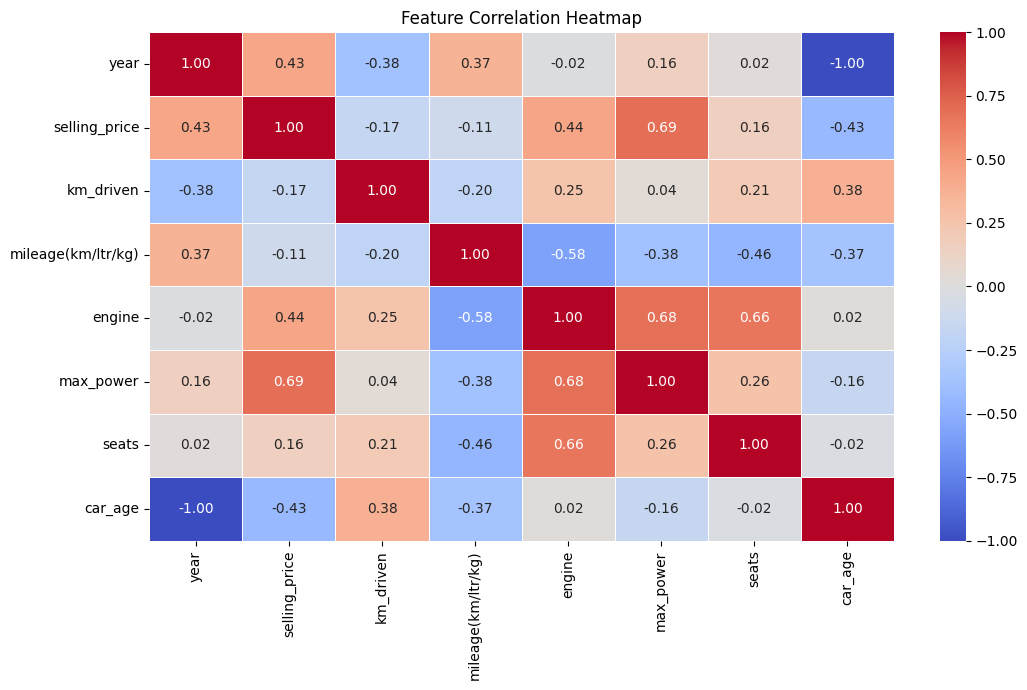

In [13]:
# Select numeric columns for correlation analysis
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlations
correlation = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [14]:
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5540
Testing samples: 1386


In [15]:
# Separate numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Process numerical columns:
# Fill missing values with the median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical columns:
# Fill missing values with the most common category
# Then convert categories into numerical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate processing to each column type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [16]:
# Create the Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Predict prices for test data
linear_predictions = linear_model.predict(X_test)

print("Linear Regression training completed!")

Linear Regression training completed!


In [17]:
# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Predict prices for test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [18]:
# Function to calculate evaluation metrics
def evaluate_model(model_name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Evaluate Linear Regression
linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

# Evaluate Random Forest
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)

# Display comparison table
results = pd.DataFrame([
    linear_results,
    rf_results
])

display(results.round(2))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,167802.14,298169.37,0.59
1,Random Forest,73576.80,129895.46,0.92


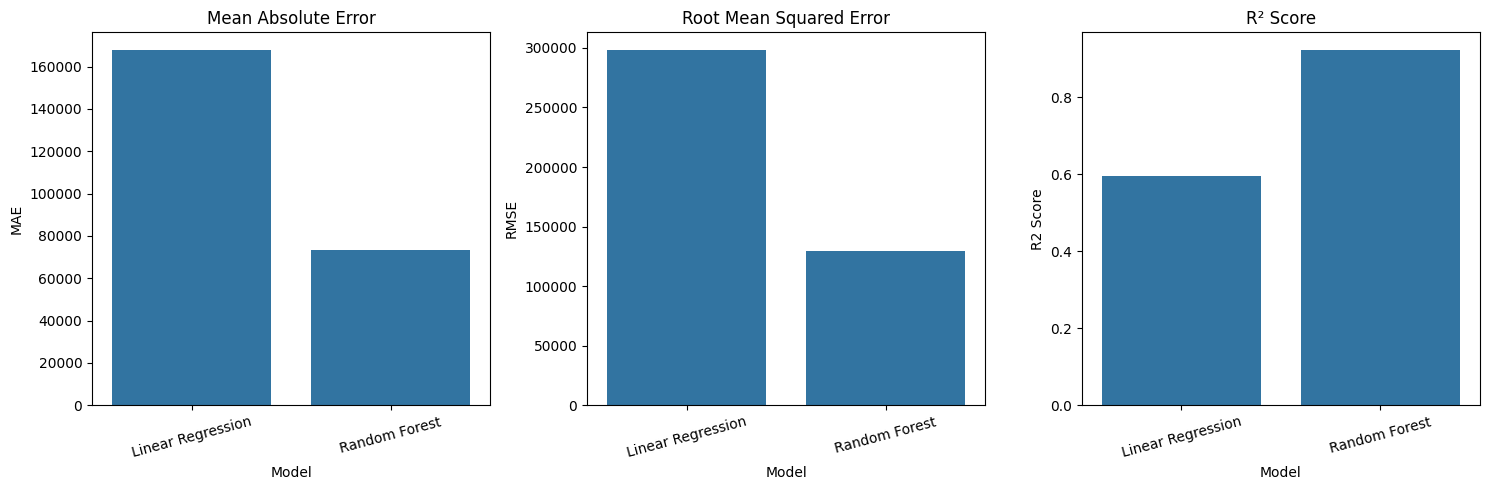

In [19]:
# Plot the comparison of evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(data=results, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=results, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=15)

sns.barplot(data=results, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Score")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

Best model: Random Forest


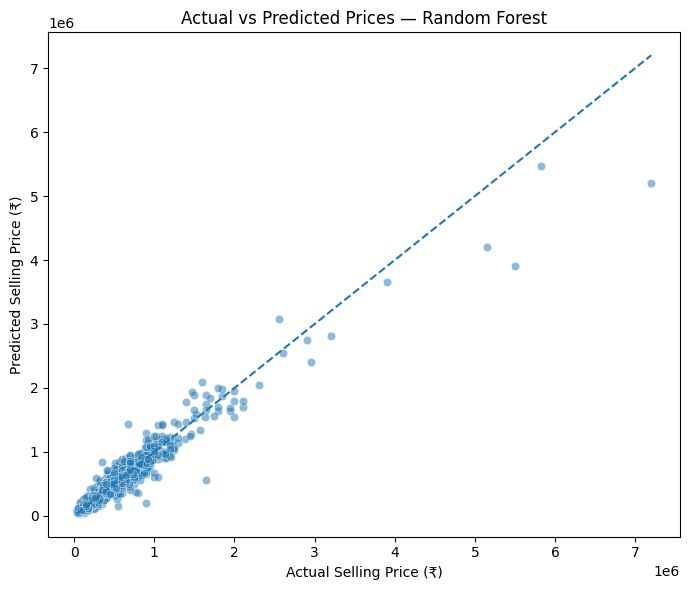

In [20]:
# Choose the model with the highest R2 score
if linear_results["R2 Score"] >= rf_results["R2 Score"]:
    best_model = linear_model
    best_predictions = linear_predictions
    best_model_name = "Linear Regression"
else:
    best_model = rf_model
    best_predictions = rf_predictions
    best_model_name = "Random Forest"

print("Best model:", best_model_name)

# Actual vs predicted plot
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.5
)

# Reference line for perfect predictions
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")

plt.tight_layout()
plt.show()

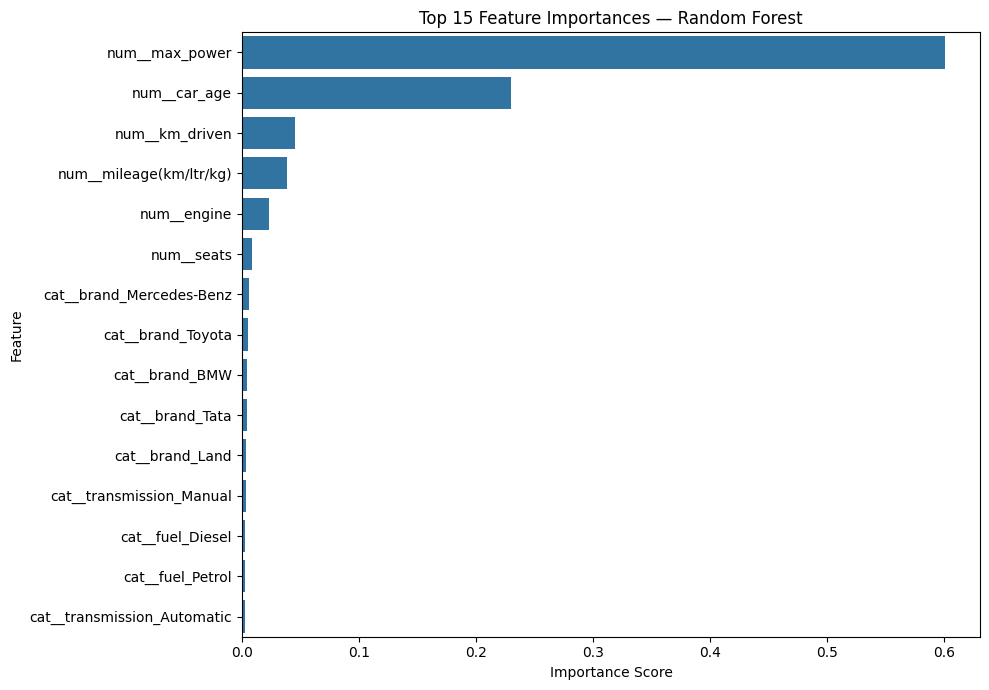

In [21]:
# Get the trained preprocessing component
trained_preprocessor = rf_model.named_steps["preprocessor"]

# Get feature names after one-hot encoding
feature_names = trained_preprocessor.get_feature_names_out()

# Get importance scores from the trained Random Forest
importances = rf_model.named_steps["model"].feature_importances_

# Create a DataFrame for feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select the 15 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Plot the chart
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [22]:
# Example details of a used car
new_car = pd.DataFrame([{
    "brand": "Maruti",
    "car_age": 5,
    "km_driven": 50000,
    "fuel": "Petrol",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "mileage(km/ltr/kg)": 20.0,
    "engine": 1200.0,
    "max_power": 85.0,
    "seats": 5.0
}])

# Predict using the best-performing model
predicted_price = best_model.predict(new_car)[0]

print("Selected model:", best_model_name)
print(f"Predicted selling price: ₹{predicted_price:,.2f}")

Selected model: Random Forest
Predicted selling price: ₹476,889.60
